# IT2226 — Step 4: EfficientNet-B0 compared with ResNet-50

**Author:** Maxime Goulème  |  **Model trained here:** EfficientNet-B0  |  **Reference:** ResNet-50 from the PR1 notebook

## Why this notebook
`requirements.md` (R2) asks to choose the final model **by comparing at least two candidates on validation**. ResNet-50 was trained in `PR1_notebook_ResNet50.ipynb`. Here we train EfficientNet-B0 with **exactly the same protocol** (same manifest, same augmentations, same class weights, same two phases, same learning-rate grid, same seed). Only the architecture changes.

## The trap avoided: the test set was already opened for ResNet-50
If we kept "the one with the best test score", the test set would be used to **choose** and would no longer measure anything impartially. So the choice rule is **fixed before training** (section 2), applied **on validation** (section 6), and **saved on Drive before opening the test set** (section 7). The test set is only used for the final report and does not change the choice.

## Before starting
You need on your Drive, with the same Google account:
- `MyDrive/dentalguide/eda_v2/`: the manifest from notebook 01;
- `MyDrive/dentalguide/pr1/`: the PR1 results (`run_info.json`, `resnet50_dental.pt`, `training_history.csv`).

## How to use it
1. Colab: **Runtime > Change runtime type > GPU (T4)**.
2. Run the cells **in order**. Do **not** change the rule of section 2 after having seen results.
3. Cells marked ✍️ contain the written interpretation of the results.

> **Note on saved outputs.** The outputs and figures saved below come from the run of 18 Nov 2026. The code comments and text were translated into English afterwards, so the printed messages and figure titles in the saved outputs are still in French. The code logic and the numbers are unchanged.

> Parts of this code were generated with the help of Claude (see the AI Use Log). Every cell has to be explainable without notes.

## 1. Setup
Parameters identical to PR1, except `MODEL_NAME` and the output folder.

In [1]:
!pip -q install kagglehub

In [2]:
import os, random, hashlib, time, json, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score
from google.colab import drive

# ---------- Parameters (identical to PR1, except MODEL_NAME and DRIVE_OUT) ----------
SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
MODEL_NAME = "efficientnet_b0"   # model trained in this notebook
REF_NAME = "resnet50"            # reference model (PR1)

MANIFEST_DIR = Path("/content/drive/MyDrive/dentalguide/eda_v2")    # notebook 01
RESNET_DIR = Path("/content/drive/MyDrive/dentalguide/pr1")         # PR1 results
DRIVE_OUT = Path("/content/drive/MyDrive/dentalguide/effnet_b0")    # results of this notebook
OUT_DIR = Path("outputs_effnet")
OUT_DIR.mkdir(exist_ok=True)

drive.mount("/content/drive")
assert (MANIFEST_DIR / "data_manifest.csv").exists(), "Manifest not found: run 01_EDA_et_manifest_v2 first"
for f in ["run_info.json", f"{REF_NAME}_dental.pt", "training_history.csv"]:
    assert (RESNET_DIR / f).exists(), f"{f} not found in {RESNET_DIR}: run the PR1 notebook first"
DRIVE_OUT.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu"
print("Device:", GPU_NAME, "| torch", torch.__version__, "| torchvision", torchvision.__version__)


def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


set_seed(SEED)

Mounted at /content/drive
Appareil : Tesla T4 | torch 2.14.1+cu130 | torchvision 0.29.1+cu130


## 2. Comparison rule — fixed **before** training
Team decision of 18/11/2026 (option B):

> EfficientNet-B0 **replaces** ResNet-50 as the final model **only if**:
> 1. its validation macro-F1 exceeds that of ResNet-50 (0.910) **by at least 0.02**;
> 2. **and** its validation recall is **≥ 0.75 for every class**.
>
> Otherwise, ResNet-50 stays the final model. Both models are then evaluated **once** on the test set, for the report, **without changing the choice**.

**Why a margin of 0.02?** Each model is trained with a single seed only: a gap of a few thousandths can come from the randomness of training. This margin is a **team decision**, not a standard. It has to be justified at the oral.

The reference macro-F1 is read back from the PR1 `run_info.json`. The rule is saved on Drive. If it already exists there with other values, the cell stops: the rule is not changed along the way.

In [3]:
ref_info = json.loads((RESNET_DIR / "run_info.json").read_text())
assert ref_info["model"] == REF_NAME

RULE = {
    "fixed_on": "2026-11-18",
    "reference_model": REF_NAME,
    "reference_val_macro_f1": ref_info["best_val_macro_f1"],   # 0.9101 at PR1
    "margin": 0.02,             # minimum gain required on the validation macro-F1
    "min_val_recall": 0.75,     # minimum validation recall, for each class
    "test_used_for_choice": False,
}

rule_file = DRIVE_OUT / "comparison_rule.json"
if rule_file.exists():
    previous = json.loads(rule_file.read_text())
    assert previous == RULE, f"Another rule is already saved on Drive: {previous}. We do not change it."
else:
    rule_file.write_text(json.dumps(RULE, indent=2))
shutil.copy(rule_file, OUT_DIR / "comparison_rule.json")

THRESHOLD = RULE["reference_val_macro_f1"] + RULE["margin"]
print(f"Rule saved: EfficientNet-B0 becomes the final model if val macro-F1 >= {THRESHOLD:.4f} "
      f"and val recall >= {RULE['min_val_recall']} for every class. Otherwise: {REF_NAME}.")

Règle enregistrée : EfficientNet-B0 devient le modèle final si macro-F1 val >= 0.9301 et rappel val >= 0.75 pour chaque classe. Sinon : resnet50.


## 3. The data (same manifest as PR1)
The EDA has already been done in notebooks 01 and PR1: we do not redo it. We download the dataset, read the manifest back, then **check** that the files and the split are exactly those of PR1. Otherwise the comparison would not be fair.

In [4]:
import kagglehub

try:
    DATA_ROOT = Path(kagglehub.dataset_download("jhirshaikh/oral-image-dataset"))
except Exception as e:
    print("Download impossible:", e)
    DATA_ROOT = Path("/content/oral-image-dataset")   # <-- adapt if needed
print("Dataset in:", DATA_ROOT)

100%|██████████| 429M/429M [00:20<00:00, 21.5MB/s]

Extracting files...


Dataset dans : /root/.cache/kagglehub/datasets/jhirshaikh/oral-image-dataset/versions/1


In [5]:
manifest = pd.read_csv(MANIFEST_DIR / "data_manifest.csv")
classes = json.loads((MANIFEST_DIR / "class_names.json").read_text())
assert classes == ref_info["classes"], "Class order different from PR1"
class_to_idx = {c: i for i, c in enumerate(classes)}

manifest["path"] = manifest.rel_path.map(lambda r: str(DATA_ROOT / r))
missing = [p for p in manifest.path if not Path(p).exists()]
assert not missing, f"{len(missing)} manifest images not found, for example {missing[:3]}"
md5 = manifest.path.map(lambda p: hashlib.md5(Path(p).read_bytes()).hexdigest())   # 1 to 2 minutes
assert (md5 == manifest.md5).all(), "A file no longer matches the manifest"
assert (manifest.label.map(class_to_idx) == manifest.y).all()

df = manifest
train_df = df[df.split == "train"].reset_index(drop=True)
val_df = df[df.split == "val"].reset_index(drop=True)
test_df = df[df.split == "test"].reset_index(drop=True)

# Same split as PR1 (2,827 / 484 / 399 images)
EXPECTED = {"train": 2827, "val": 484, "test": 399}
assert {"train": len(train_df), "val": len(val_df), "test": len(test_df)} == EXPECTED, "Split different from PR1"
assert df.groupby("group_id").split.nunique().max() == 1, "A group of copies is split between two sets!"
print("Same manifest and same split as PR1:", EXPECTED)

Même manifest et même découpage que le PR1 : {'train': 2827, 'val': 484, 'test': 399}


## 4. Preprocessing, loaders and class weights (identical to PR1)
We keep **exactly** the PR1 preprocessing for both models, so that only the architecture differs.

*Remark:* the torchvision documentation proposes a slightly different preprocessing for EfficientNet-B0 (resizing method). To be checked in the documentation if a jury asks. We chose the common preprocessing, for fairness.

In [6]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet, as in PR1
assert MEAN == ref_info["mean"] and STD == ref_info["std"] and IMG_SIZE == ref_info["img_size"]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


class OralDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths = frame.path.tolist()
        self.labels = frame.y.tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]


pin = DEVICE.type == "cuda"
train_loader = DataLoader(OralDataset(train_df, train_tf), batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin)
val_loader = DataLoader(OralDataset(val_df, eval_tf), batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=pin)
test_loader = DataLoader(OralDataset(test_df, eval_tf), batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=pin)

train_counts = np.bincount(train_df.y, minlength=len(classes))
class_weights = torch.tensor(train_counts.sum() / (len(classes) * train_counts), dtype=torch.float32)
print(pd.DataFrame({"class": classes, "train images": train_counts, "weight": class_weights.numpy().round(2)}).to_string(index=False))

             classe  images train  poids
           Calculus           593   0.79
             Caries           136   3.46
         Hypodontia           907   0.52
        Mouth Ulcer           178   2.65
             Normal           215   2.19
Tooth Discoloration           798   0.59


## 5. The model and the training (same code as PR1)
**EfficientNet-B0** is another family of networks: instead of stacking residual blocks like ResNet, it uses lighter "separable" convolutions and was sized to obtain a good accuracy with few parameters. Its last layer (`classifier`) is replaced by the **same head** as ResNet-50: `Dropout(0.3)` then a linear layer with 6 outputs.

The two phases (head only, then whole network with a lower learning rate for the body) and the selection on validation macro-F1 are **identical** to PR1.

In [7]:
def build_model(name, n_classes, pretrained=True):
    # Loads a model (ImageNet pre-trained if pretrained) and replaces its last layer.
    if name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, n_classes))
    elif name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.classifier[1].in_features, n_classes))
    else:
        raise ValueError("Unknown model: " + name)
    return m.to(DEVICE)


def head_params(m):
    return (m.fc if hasattr(m, "fc") else m.classifier).parameters()


def set_backbone_trainable(m, trainable):
    head_ids = {id(p) for p in head_params(m)}
    for p in m.parameters():
        p.requires_grad = True if id(p) in head_ids else trainable


n_params = {}
for name in [REF_NAME, MODEL_NAME]:
    m = build_model(name, len(classes), pretrained=False)
    n_params[name] = sum(p.numel() for p in m.parameters())
    print(f"{name:16s}: {n_params[name]/1e6:.2f} M parameters (6-class head included)")
    del m

resnet50        : 23.52 M de paramètres (tête à 6 classes incluse)
efficientnet_b0 : 4.02 M de paramètres (tête à 6 classes incluse)


In [8]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss, preds, labels = 0.0, [], []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
                out = model(x)
                loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
        total_loss += loss.item() * x.size(0)
        preds += out.argmax(1).cpu().tolist()
        labels += y.cpu().tolist()
    n = len(labels)
    acc = float(np.mean(np.array(preds) == np.array(labels)))
    macro_f1 = f1_score(labels, preds, average="macro")
    return total_loss / n, acc, macro_f1


def run_experiment(tag, lr_head, lr_backbone, epochs_head, epochs_ft, verbose=True):
    # Identical to PR1: phase 1 (head only) then phase 2 (whole network).
    set_seed(SEED)
    model = build_model(MODEL_NAME, len(classes))
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
    history, best_f1, best_state, baseline_f1 = [], -1.0, None, None

    def one_phase(phase, epochs, optimizer, scheduler):
        nonlocal best_f1, best_state
        for ep in range(1, epochs + 1):
            tr_loss, tr_acc, tr_f1 = run_epoch(model, train_loader, criterion, optimizer, scaler)
            va_loss, va_acc, va_f1 = run_epoch(model, val_loader, criterion)
            if scheduler:
                scheduler.step()
            history.append(dict(tag=tag, phase=phase, epoch=ep, train_loss=tr_loss, val_loss=va_loss,
                                train_f1=tr_f1, val_f1=va_f1, val_acc=va_acc))
            if verbose:
                print(f"[{tag}|{phase}] epoch {ep}/{epochs} train_loss {tr_loss:.3f} | "
                      f"val_loss {va_loss:.3f} val_acc {va_acc:.3f} val_macroF1 {va_f1:.3f}")
            if va_f1 > best_f1:
                best_f1 = va_f1
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    set_backbone_trainable(model, False)
    opt1 = torch.optim.AdamW(head_params(model), lr=lr_head, weight_decay=1e-4)
    one_phase("phase1_head", epochs_head, opt1, None)
    baseline_f1 = best_f1

    set_backbone_trainable(model, True)
    head_ids = {id(p) for p in head_params(model)}
    backbone = [p for p in model.parameters() if id(p) not in head_ids]
    opt2 = torch.optim.AdamW([{"params": backbone, "lr": lr_backbone},
                              {"params": list(head_params(model)), "lr": lr_head / 10}], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt2, T_max=epochs_ft)
    one_phase("phase2_finetuning", epochs_ft, opt2, sched)

    return dict(tag=tag, lr_head=lr_head, lr_backbone=lr_backbone, baseline_val_f1=baseline_f1,
                best_val_f1=best_f1, best_state=best_state, history=pd.DataFrame(history))

### 5.1 Quick trial (1 epoch per phase)
We check that everything runs before the real trials.

In [9]:
t0 = time.time()
smoke = run_experiment("quick_test", lr_head=1e-3, lr_backbone=1e-4, epochs_head=1, epochs_ft=1)
print(f"OK in {time.time() - t0:.0f} s | val macro-F1: {smoke['best_val_f1']:.3f}")
del smoke

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 223MB/s]


[test_rapide|phase1_tete] epoch 1/1 train_loss 1.287 | val_loss 0.828 val_acc 0.808 val_macroF1 0.746
[test_rapide|phase2_finetuning] epoch 1/1 train_loss 0.620 | val_loss 0.342 val_acc 0.907 val_macroF1 0.879
OK en 96 s | macro-F1 val : 0.879


### 5.2 Same learning-rate grid as PR1
Same epochs (3 + 8) and same three learning rates for the body. We also measure the **total duration** of this grid.

*Limit to know:* these learning rates were chosen for ResNet-50. EfficientNet-B0 may prefer other values. We keep the same grid for fairness and note this limit in the conclusion.

In [10]:
EPOCHS_HEAD = 3
EPOCHS_FT = 8
LR_HEAD = 1e-3
LR_BACKBONE_CANDIDATES = [3e-5, 1e-4, 3e-4]

t_grid = time.time()
experiments = []
for lr_bb in LR_BACKBONE_CANDIDATES:
    print(f"\n===== {MODEL_NAME} | lr_backbone = {lr_bb} =====")
    experiments.append(run_experiment(f"lr_bb={lr_bb:g}", LR_HEAD, lr_bb, EPOCHS_HEAD, EPOCHS_FT))
GRID_MINUTES = (time.time() - t_grid) / 60
print(f"\nDuration of the grid (3 trials): {GRID_MINUTES:.1f} min on {GPU_NAME}")

results = pd.DataFrame([{k: v for k, v in e.items() if k not in ("best_state", "history")} for e in experiments])
results = results.sort_values("best_val_f1", ascending=False).reset_index(drop=True)
results.to_csv(OUT_DIR / "hyperparameter_results.csv", index=False)
results


===== efficientnet_b0 | lr_backbone = 3e-05 =====
[lr_bb=3e-05|phase1_tete] epoch 1/3 train_loss 1.287 | val_loss 0.828 val_acc 0.808 val_macroF1 0.746
[lr_bb=3e-05|phase1_tete] epoch 2/3 train_loss 0.857 | val_loss 0.680 val_acc 0.812 val_macroF1 0.769
[lr_bb=3e-05|phase1_tete] epoch 3/3 train_loss 0.740 | val_loss 0.565 val_acc 0.841 val_macroF1 0.785
[lr_bb=3e-05|phase2_finetuning] epoch 1/8 train_loss 0.574 | val_loss 0.432 val_acc 0.880 val_macroF1 0.845
[lr_bb=3e-05|phase2_finetuning] epoch 2/8 train_loss 0.423 | val_loss 0.378 val_acc 0.884 val_macroF1 0.851
[lr_bb=3e-05|phase2_finetuning] epoch 3/8 train_loss 0.326 | val_loss 0.326 val_acc 0.901 val_macroF1 0.873
[lr_bb=3e-05|phase2_finetuning] epoch 4/8 train_loss 0.271 | val_loss 0.297 val_acc 0.905 val_macroF1 0.876
[lr_bb=3e-05|phase2_finetuning] epoch 5/8 train_loss 0.233 | val_loss 0.277 val_acc 0.919 val_macroF1 0.892
[lr_bb=3e-05|phase2_finetuning] epoch 6/8 train_loss 0.204 | val_loss 0.283 val_acc 0.907 val_macroF1 0

,tag,lr_head,lr_backbone,baseline_val_f1,best_val_f1
0,lr_bb=0.0003,0.001,0.00030,0.785456,0.933441
1,lr_bb=0.0001,0.001,0.00010,0.785456,0.917227
2,lr_bb=3e-05,0.001,0.00003,0.785456,0.891788


Meilleur essai EfficientNet-B0 (VALIDATION) : lr_bb=0.0003 | macro-F1 val 0.9334 (tête seule : 0.7855)


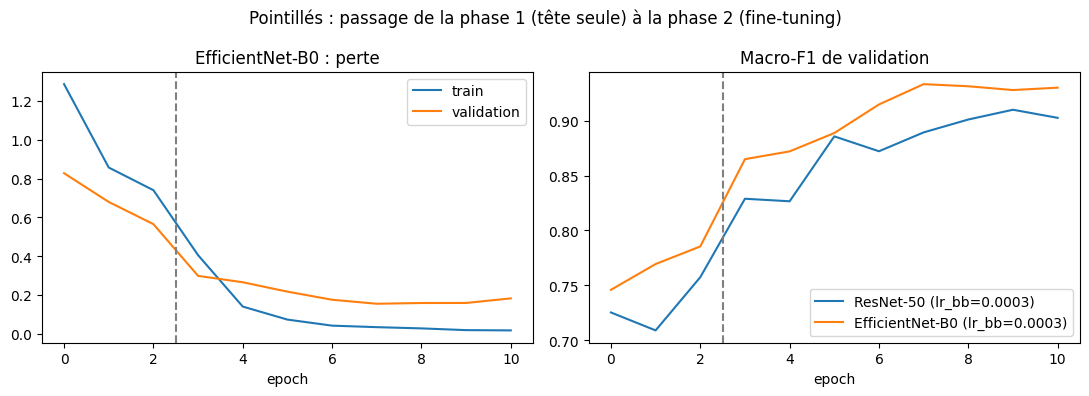

In [11]:
best = max(experiments, key=lambda e: e["best_val_f1"])
print(f"Best EfficientNet-B0 trial (VALIDATION): {best['tag']} | val macro-F1 {best['best_val_f1']:.4f} "
      f"(head only: {best['baseline_val_f1']:.4f})")

# Validation curve of both models, each with its best learning rate
h_eff = best["history"].reset_index(drop=True)
h_ref = pd.read_csv(RESNET_DIR / "training_history.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h_eff.train_loss, label="train"); ax[0].plot(h_eff.val_loss, label="validation")
ax[0].axvline(EPOCHS_HEAD - 0.5, color="gray", ls="--"); ax[0].set_title("EfficientNet-B0: loss"); ax[0].legend()
ax[0].set_xlabel("epoch")
ax[1].plot(h_ref.val_f1.values, label=f"ResNet-50 ({ref_info['best_experiment']})")
ax[1].plot(h_eff.val_f1, label=f"EfficientNet-B0 ({best['tag']})")
ax[1].axvline(EPOCHS_HEAD - 0.5, color="gray", ls="--"); ax[1].set_title("Validation macro-F1"); ax[1].legend()
ax[1].set_xlabel("epoch")
fig.suptitle("Dashed line: switch from phase 1 (head only) to phase 2 (fine-tuning)")
fig.tight_layout()
fig.savefig(OUT_DIR / "training_curves_comparison.png", dpi=150)
plt.show()

✍️ **Interpretation of the training**
- **Best learning rate.** 3e-4 is the best for EfficientNet-B0 too (validation macro-F1 0.933), followed by 1e-4 (0.917) and 3e-5 (0.892): the same ranking as for ResNet-50 (0.910, 0.908, 0.879). Here the gap between 3e-4 and 1e-4 (0.016) is larger than for ResNet-50 (0.003). 3e-4 is again the largest value tested, so a higher value was not explored.
- **Gain of fine-tuning.** From 0.785 (head only) to 0.933: +0.148, similar to the +0.153 obtained with ResNet-50 (0.757 → 0.910). The head-only baseline is higher for EfficientNet-B0.
- **Overfitting.** Mild: at 3e-4 the training loss falls to about 0.02 while the validation loss stays around 0.16 to 0.18 and rises slightly after epoch 5 of phase 2, where the validation macro-F1 peaks (0.933). The kept weights come from that epoch.

## 6. Applying the rule, **on validation only**
- **Macro-F1**: we compare the value kept during selection, computed in the same way as the 0.9101 of ResNet-50 at PR1.
- **Recalls**: we properly re-evaluate the best EfficientNet-B0 on validation.
- We also reload the PR1 ResNet-50 and evaluate it on validation, for the final table. Its macro-F1 must be very close to 0.910; a small difference is possible because of the mixed-precision computation.

The decision is **saved on Drive before** section 7.

In [12]:
def predict(model, loader):
    model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            ps += model(x.to(DEVICE)).argmax(1).cpu().tolist()
            ys += y.tolist()
    return np.array(ys), np.array(ps)


eff_model = build_model(MODEL_NAME, len(classes), pretrained=False)
eff_model.load_state_dict(best["best_state"])
ref_model = build_model(REF_NAME, len(classes), pretrained=False)
ref_model.load_state_dict(torch.load(RESNET_DIR / f"{REF_NAME}_dental.pt", map_location=DEVICE))

yv, pv_eff = predict(eff_model, val_loader)
_, pv_ref = predict(ref_model, val_loader)
print("=== VALIDATION — EfficientNet-B0 ===")
print(classification_report(yv, pv_eff, target_names=classes, digits=3))
print("=== VALIDATION — ResNet-50 (reloaded from PR1) ===")
print(classification_report(yv, pv_ref, target_names=classes, digits=3))

eff_val_f1 = float(best["best_val_f1"])
eff_val_recall = recall_score(yv, pv_eff, average=None, labels=range(len(classes)))
cond_f1 = eff_val_f1 >= THRESHOLD
low = [classes[i] for i, r in enumerate(eff_val_recall) if r < RULE["min_val_recall"]]
cond_recall = not low
FINAL_MODEL = MODEL_NAME if (cond_f1 and cond_recall) else REF_NAME

decision = {
    "decided_on_validation_only": True,
    "efficientnet_val_macro_f1": round(eff_val_f1, 4),
    "threshold": round(THRESHOLD, 4),
    "condition_macro_f1": bool(cond_f1),
    "classes_below_min_recall": low,
    "condition_recall": bool(cond_recall),
    "final_model": FINAL_MODEL,
}
decision_file = DRIVE_OUT / "decision.json"
if decision_file.exists():
    print("Decision already saved during a previous run:", json.loads(decision_file.read_text()))
decision_file.write_text(json.dumps(decision, indent=2))
shutil.copy(decision_file, OUT_DIR / "decision.json")

print(f"EfficientNet-B0 val macro-F1 {eff_val_f1:.4f} >= {THRESHOLD:.4f}: {'YES' if cond_f1 else 'NO'}")
print("Classes below the minimum recall:", low if low else "none")
print(f"\n==> FINAL MODEL (decided on validation): {FINAL_MODEL}")

=== VALIDATION — EfficientNet-B0 ===
                     precision    recall  f1-score   support

           Calculus      0.967     0.937     0.952        95
             Caries      0.675     0.900     0.771        30
         Hypodontia      0.983     0.983     0.983       172
        Mouth Ulcer      0.971     1.000     0.985        33
             Normal      0.971     0.944     0.958        36
Tooth Discoloration      0.982     0.924     0.952       118

           accuracy                          0.952       484
          macro avg      0.925     0.948     0.933       484
       weighted avg      0.959     0.952     0.954       484

=== VALIDATION — ResNet-50 (rechargé depuis le PR1) ===
                     precision    recall  f1-score   support

           Calculus      0.975     0.821     0.891        95
             Caries      0.547     0.967     0.699        30
         Hypodontia      0.988     0.959     0.973       172
        Mouth Ulcer      0.971     1.000     0.98

## 7. Test: only once, for the report
The choice is made and saved. We now evaluate both models on the test set. **These results do not change the choice.**

For ResNet-50, we must find the PR1 results again (macro-F1 0.904, 29 errors): this is also a reproducibility check.

We also read back the PR1 success criteria (macro-F1 ≥ 0.80, recall ≥ 0.75 per pathological class) to position EfficientNet-B0.

In [13]:
assert (DRIVE_OUT / "decision.json").exists(), "The decision must be saved before opening the test set (section 6)."

yt, pt_eff = predict(eff_model, test_loader)
_, pt_ref = predict(ref_model, test_loader)
crit = ref_info["success_criteria"]
pathological = [i for i, c in enumerate(classes) if c != "Normal"]

for name, pt in [(REF_NAME, pt_ref), (MODEL_NAME, pt_eff)]:
    f1 = f1_score(yt, pt, average="macro")
    rec = recall_score(yt, pt, average=None, labels=range(len(classes)))
    low_t = [classes[i] for i in pathological if rec[i] < crit["min_recall"]]
    print(f"=== TEST — {name} | accuracy {(yt == pt).mean():.3f} | macro-F1 {f1:.3f} | "
          f"errors {(yt != pt).sum()}/{len(yt)} ===")
    print(classification_report(yt, pt, target_names=classes, digits=3))
    print(f"PR1 criteria: macro-F1 >= {crit['min_macro_f1']}: {'YES' if f1 >= crit['min_macro_f1'] else 'NO'} | "
          f"pathological classes below {crit['min_recall']}: {low_t if low_t else 'none'}\n")

(OUT_DIR / "classification_report_test.txt").write_text(
    classification_report(yt, pt_eff, target_names=classes, digits=3))

=== TEST — resnet50 | accuracy 0.927 | macro-F1 0.904 | erreurs 29/399 ===
                     precision    recall  f1-score   support

           Calculus      0.946     0.795     0.864        44
             Caries      0.657     0.821     0.730        28
         Hypodontia      0.953     0.972     0.962       145
        Mouth Ulcer      0.903     0.966     0.933        29
             Normal      1.000     1.000     1.000        33
Tooth Discoloration      0.957     0.917     0.936       120

           accuracy                          0.927       399
          macro avg      0.903     0.912     0.904       399
       weighted avg      0.933     0.927     0.928       399

Critères PR1 : macro-F1 >= 0.8 : OUI | classes pathologiques sous 0.75 : aucune

=== TEST — efficientnet_b0 | accuracy 0.935 | macro-F1 0.907 | erreurs 26/399 ===
                     precision    recall  f1-score   support

           Calculus      0.878     0.818     0.847        44
             Caries      0

612

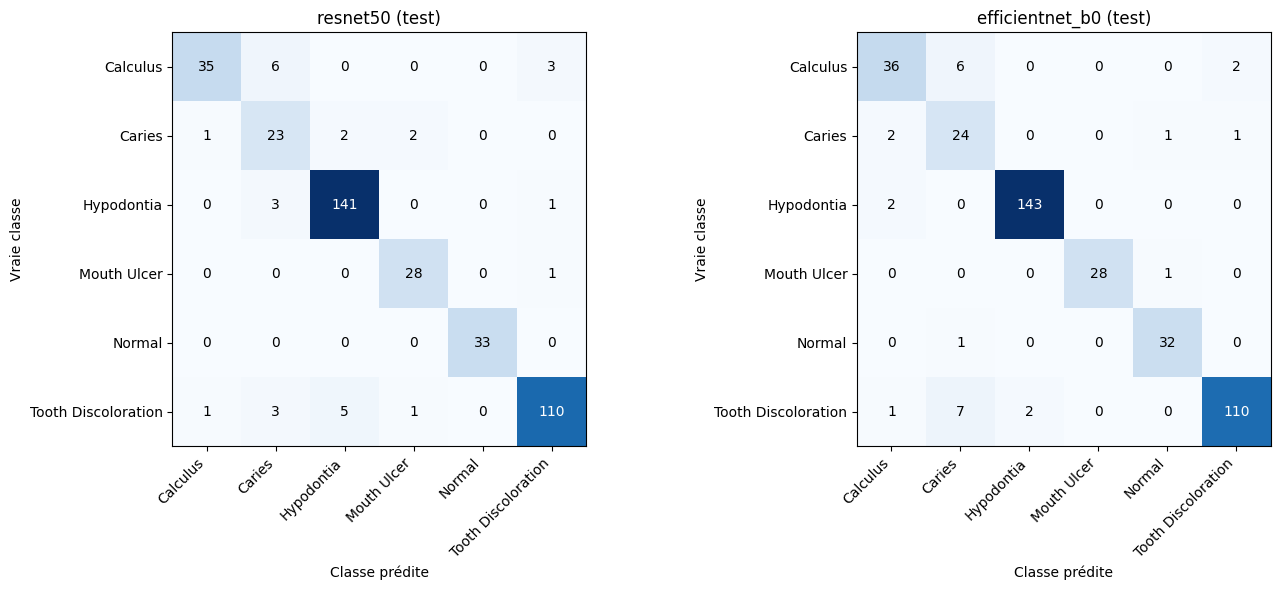

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, pt) in zip(axes, [(REF_NAME, pt_ref), (MODEL_NAME, pt_eff)]):
    cm = confusion_matrix(yt, pt, labels=range(len(classes)))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=45, ha="right")
    ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(f"{name} (test)")
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.tight_layout()
fig.savefig(OUT_DIR / "confusion_matrices_comparison.png", dpi=150)
plt.show()

## 8. Comparison table
We add two measurements that are useful for the local application (step 6):
- **Model size** (number of parameters and megabytes of weights);
- **Inference time**: on the Colab GPU (batch of 32 images) and on the **Colab CPU** (1 image at a time, closer to the use in the application). These are **not** the times of the team's machine: only a relative order of magnitude between the two models. Image loading is not counted.

The training duration of ResNet-50 was not measured at PR1: it appears as "not measured".

In [15]:
def ms_gpu_batch(model, loader, n_batches=10):
    # milliseconds per image, batches of BATCH_SIZE, on the GPU (image loading excluded)
    if DEVICE.type != "cuda":
        return float("nan")
    model.eval(); total_t, total_n = 0.0, 0
    with torch.no_grad():
        for i, (x, _) in enumerate(loader):
            x = x.to(DEVICE)
            if i == 0:
                model(x); torch.cuda.synchronize(); continue   # warm-up
            t = time.perf_counter(); model(x); torch.cuda.synchronize()
            total_t += time.perf_counter() - t; total_n += x.size(0)
            if i >= n_batches:
                break
    return 1000 * total_t / total_n


def ms_cpu_single(model, n_images=20):
    # milliseconds per image, one image at a time, on the Colab CPU
    m = model.to("cpu").eval()
    x = torch.stack([eval_tf(Image.open(p).convert("RGB")) for p in val_df.path[:n_images]])
    with torch.no_grad():
        m(x[:1])   # warm-up
        t = time.perf_counter()
        for i in range(n_images):
            m(x[i:i + 1])
    model.to(DEVICE)
    return 1000 * (time.perf_counter() - t) / n_images


def size_mb(model):
    return sum(v.numel() * v.element_size() for v in model.state_dict().values()) / 1e6


def column(name, model, val_f1_sel, pv, pt, train_minutes):
    rv = recall_score(yv, pv, average=None, labels=range(len(classes)))
    rt = recall_score(yt, pt, average=None, labels=range(len(classes)))
    col = {
        "parameters (M)": round(n_params[name] / 1e6, 2),
        "weights (MB)": round(size_mb(model), 1),
        "LR grid duration (min)": train_minutes,
        "VAL macro-F1 (selection)": round(val_f1_sel, 4),
    }
    col.update({f"VAL recall {c}": round(float(r), 3) for c, r in zip(classes, rv)})
    col["TEST accuracy"] = round(float((yt == pt).mean()), 4)
    col["TEST macro-F1"] = round(float(f1_score(yt, pt, average="macro")), 4)
    col.update({f"TEST recall {c}": round(float(r), 3) for c, r in zip(classes, rt)})
    col["TEST errors"] = int((yt != pt).sum())
    col["GPU inference (ms/image, batch 32)"] = round(ms_gpu_batch(model, val_loader), 2)
    col["Colab CPU inference (ms/image, 1 image)"] = round(ms_cpu_single(model), 1)
    return col


comparison = pd.DataFrame({
    "ResNet-50": column(REF_NAME, ref_model, ref_info["best_val_macro_f1"], pv_ref, pt_ref, "not measured"),
    "EfficientNet-B0": column(MODEL_NAME, eff_model, eff_val_f1, pv_eff, pt_eff, round(GRID_MINUTES, 1)),
})
comparison.to_csv(OUT_DIR / "comparison.csv")
print(f"Final model (rule applied on validation): {FINAL_MODEL}")
comparison

Modèle final (règle appliquée sur la validation) : efficientnet_b0


,ResNet-50,EfficientNet-B0
paramètres (M),23.52,4.0200
poids (Mo),94.3,16.2000
durée grille LR (min),non mesurée,22.4000
VAL macro-F1 (sélection),0.9101,0.9334
VAL rappel Calculus,0.821,0.9370
VAL rappel Caries,0.967,0.9000
VAL rappel Hypodontia,0.959,0.9830
VAL rappel Mouth Ulcer,1.0,1.0000
VAL rappel Normal,0.972,0.9440
VAL rappel Tooth Discoloration,0.924,0.9240


✍️ **Comparison conclusion**
- **The rule.** EfficientNet-B0 replaces ResNet-50 only if its validation macro-F1 is at least 0.9301 (0.910 + 0.02) and every validation recall is at least 0.75. A margin was fixed *before* training because each model is trained once: a small gap can be luck. Result: 0.9334 ≥ 0.9301 and the lowest recall is 0.900 (Caries), so the rule is met and **EfficientNet-B0 is the final model**. The margin is passed only narrowly (0.003 above the threshold).
- **Validation, then test.** On validation the gap is +0.023 (0.933 vs 0.910). On test it is only +0.003 in macro-F1 (0.907 vs 0.904), +0.8 points of accuracy (93.5% vs 92.7%) and 3 fewer errors (26 vs 29 out of 399). With one seed and 399 images, the test gap is within noise: we do **not** claim that EfficientNet-B0 is more accurate, only that it is at least as good here.
- **Same errors?** Calculus and Caries remain the weakest classes for both models (test recall Calculus 0.795 → 0.818, Caries 0.821 → 0.857; Caries precision 0.657 → 0.632). We did not compare the two confusion matrices image by image. One difference to check: ResNet-50 has a perfect score on Normal (1.000/1.000), whereas EfficientNet-B0 has recall 0.970 and precision 0.941, which suggests that a couple of diseased images are predicted as Normal, a more serious error in screening. To be checked in the confusion matrix.
- **Size and speed.** EfficientNet-B0 has 4.02 M parameters against 23.52 M, weights of 16.2 MB against 94.3 MB, and runs in 34 ms per image on a Colab CPU against 117 ms (1.4 ms against 3.3 ms per image on the GPU, in batches). For a local application it is clearly more attractive, even at equal performance. The fixed rule, however, only takes validation performance into account.
- **Limits.** One seed per model; the learning-rate grid was chosen for ResNet-50; the timings were measured on Colab and not on our machine; the rule was fixed after the ResNet-50 test score had already been seen (but before any EfficientNet training); the validation score is optimistic because it was used for selection.

## 9. Saving
Everything is copied to `MyDrive/dentalguide/effnet_b0/`. The weights (`.pt`) stay on Drive, like those of ResNet-50; the other files are to be imported into `data/effnet_b0/` of the repository.

In [16]:
torch.save(best["best_state"], OUT_DIR / f"{MODEL_NAME}_dental.pt")
(OUT_DIR / "classes.json").write_text(json.dumps(classes))
best["history"].to_csv(OUT_DIR / "training_history.csv", index=False)

run_info = {
    "model": MODEL_NAME,
    "classes": classes,
    "best_experiment": best["tag"],
    "best_val_macro_f1": round(eff_val_f1, 4),
    "test_accuracy": round(float((yt == pt_eff).mean()), 4),
    "test_macro_f1": round(float(f1_score(yt, pt_eff, average="macro")), 4),
    "comparison_rule": RULE,
    "final_model_by_rule": FINAL_MODEL,
    "split_source": "data_manifest.csv (01_EDA_et_manifest_v2)",
    "img_size": IMG_SIZE, "mean": MEAN, "std": STD,
    "torch": torch.__version__, "torchvision": torchvision.__version__, "seed": SEED,
    "gpu": GPU_NAME, "grid_minutes": round(GRID_MINUTES, 1),
}
(OUT_DIR / "run_info.json").write_text(json.dumps(run_info, indent=2))

shutil.copytree(OUT_DIR, DRIVE_OUT, dirs_exist_ok=True)
print("Files saved on Drive:", sorted(p.name for p in DRIVE_OUT.iterdir()))

Fichiers sauvegardés sur Drive : ['classes.json', 'classification_report_test.txt', 'comparison.csv', 'comparison_rule.json', 'confusion_matrices_comparison.png', 'decision.json', 'efficientnet_b0_dental.pt', 'hyperparameter_results.csv', 'run_info.json', 'training_curves_comparison.png', 'training_history.csv']


## 10. Checklist
- [x] The rule of section 2 was not modified after seeing results
- [x] Notebook run **from top to bottom** without error, all outputs visible
- [x] The reloaded ResNet-50 gives the PR1 test results again (macro-F1 0.904, 29 errors)
- [x] The 2 ✍️ cells are filled in
- [ ] Files of `MyDrive/dentalguide/effnet_b0/` (except the `.pt`) imported into `data/effnet_b0/`
- [ ] AI Use Log updated